In [22]:
import sunpy
import sunpy.timeseries 
from sunpy.net import Fido, attrs as a
import matplotlib.pyplot as plt
import sunpy.map
import numpy as np


In [23]:

from astropy.visualization import time_support

from sunpy import timeseries as ts


In [29]:
tstart = "2010-6-21 1:00"
tend = "2010-6-21 1:00"

result = Fido.search(a.Time(tstart, tend), a.Instrument("XRS"), a.Resolution("flx1s"))
print(result)

Results from 1 Provider:

1 Results from the XRSClient:
Source: <8: https://umbra.nascom.nasa.gov/goes/fits 
8-15: https://www.ncei.noaa.gov/data/goes-space-environment-monitor/access/science/ 
16-17: https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/

       Start Time               End Time        Instrument  Physobs   Source Provider Resolution SatelliteNumber filename_res
----------------------- ----------------------- ---------- ---------- ------ -------- ---------- --------------- ------------
2010-06-21 00:00:00.000 2010-06-21 23:59:59.999        XRS irradiance   GOES     NOAA      irrad              14         gxrs




In [20]:
downloaded_files = Fido.fetch(result, path='./GOES _XRS_Data/')

Files Downloaded: 100%|████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  3.82file/s]


In [19]:
print(downloaded_files)

['GOES _XRS_Data/sci_gxrs-l2-irrad_g14_d20100621_v0-1-0.nc', 'GOES _XRS_Data/sci_gxrs-l2-irrad_g14_d20100622_v0-1-0.nc']


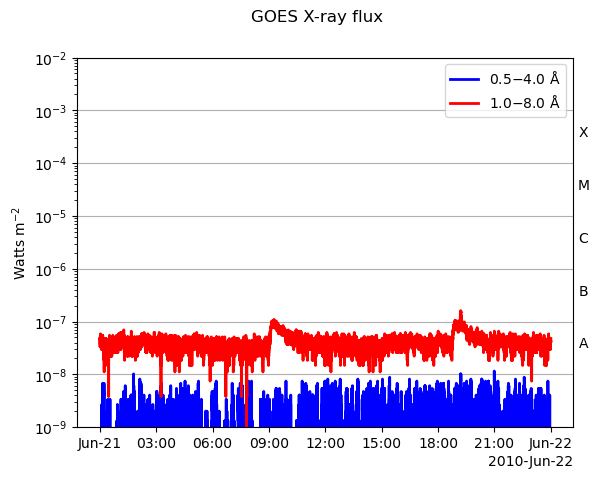

In [16]:
goes_15 = ts.TimeSeries(downloaded_files[0])
goes_15.peek()

In [18]:
goes = ts.TimeSeries(downloaded_files[0])

# Select the time range (UTC)
start_time = "2010-06-21 08:00"
end_time   = "2010-06-21 10:00"

goes_range = goes.truncate(start_time, end_time)

# GOES long-wavelength channel: 1–8 Å
flux = goes_range.to_dataframe()["xrsb"]

# Find peak flux and its time
peak_time = flux.idxmax()
peak_flux = flux.max()

print(f"Peak time: {peak_time}")
print(f"Peak flux: {peak_flux:.4e} W/m²")

Peak time: 2010-06-21 09:16:03.665000
Peak flux: 1.0954e-07 W/m²
